# Shop the Look
### Semantic segmentation for a fashion marketplace

---

## The business problem

A shopper sees an outfit they like — on the street, on a friend, in a magazine — takes a
photograph, and opens your app. They want to buy something in that picture.

Last week's model could tell them *"this photograph contains a coat."* That is useless.
You cannot shop a sentence. To search your catalog you need the **coat itself**: the
pixels, cut out, ready to match against product images.

That is the difference between classification and segmentation, and it is the whole
reason this second notebook exists.

| | Classification | Segmentation |
|---|---|---|
| Question | What is in this photo? | What is **this pixel**? |
| Output | one label | one label per pixel |
| Output size | 7 numbers | 7 numbers x 12,288 pixels |
| Business use | tagging a listing | cropping a garment to search with |

Pinterest Lens, Google Lens and Myntra's visual search all run on this idea.

---

## What you will build

A network that takes a street-fashion photograph and colours in every pixel as
background, skin, top, bottom, dress, footwear or bag. Then you will use those regions
to cut each garment out of the photo.

Along the way you will build **two** networks — one deliberately crippled — to see
exactly why segmentation architectures are shaped the way they are.

**Runtime:** about 10 minutes on a laptop CPU. **Downloads:** none.

In [1]:
!git --version

git version 2.43.0


In [2]:
!git config --global user.name "Sumit Kumar"
!git config --global user.email "sk681172112209@gmail.com"

In [5]:
import os

print("Notebook files:")
for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d != ".config"]
    for f in files:
        if f.endswith((".ipynb", ".pt", ".pth", ".npz")):
            print(os.path.join(root, f))

print("\nModel variables still in memory:")
print("unet exists:", "unet" in globals())
print("miou_unet exists:", "miou_unet" in globals())
print("CLASSES exists:", "CLASSES" in globals())

Notebook files:

Model variables still in memory:
unet exists: False
miou_unet exists: False
CLASSES exists: False


> ### About the data
>
> **Clothing Co-Parsing** (Yang et al.), 1,004 street-fashion photographs where a human
> has labelled **every pixel** with one of 59 garment tags. Released under Apache 2.0.
>
> Pixel labelling is slow and expensive — roughly an hour per image — which is why
> segmentation datasets are small and why this one has a thousand images rather than a
> million. That constraint shapes everything we do below.
>
> We collapse the 59 original tags into **7 classes** a marketplace actually cares about.
> Nobody needs to distinguish loafers from pumps before they have found the shoe.
>
> Ships with this notebook as `fashion_parsing.npz` (5.5 MB).
> Source: <https://github.com/bearpaw/clothing-co-parsing>

## 0. Setup

In [ ]:
import io, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch, Patch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from PIL import Image

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MAROON, SLATE, TEAL, AMBER, GREY = "#8C1515", "#2F4858", "#0E6E5C", "#C97B12", "#B9BFC4"
plt.rcParams.update({"figure.dpi": 100, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
print(f"torch {torch.__version__}  |  device {DEVICE}")

torch 2.11.0+cu130  |  device cuda


## 1. Load the photographs and their masks

Every photograph comes with a **mask** — an array of exactly the same width and height,
where each entry is a class number from 0 to 6 saying what that pixel belongs to.

In [ ]:
data = np.load("fashion_parsing.npz")
blob, off = data["image_jpeg"], data["image_off"]
MASKS = data["masks"].astype(np.int64)
CLASSES = [str(c) for c in data["classes"]]
W, H = (int(v) for v in data["size"])
N = len(MASKS)

def photo(i):
    return np.asarray(Image.open(io.BytesIO(blob[off[i]:off[i+1]].tobytes())), dtype=np.uint8)

IMAGES = np.stack([photo(i) for i in range(N)])

# one colour per class, used in every figure from here on
PALETTE = np.array([[20, 24, 28], [242, 205, 178], [140, 21, 21], [47, 72, 88],
                    [201, 123, 18], [14, 110, 92], [122, 90, 160]], dtype=np.uint8)
def colourise(m): return PALETTE[m]
LEGEND = [Patch(facecolor=PALETTE[i]/255, label=f"{i}  {c}") for i, c in enumerate(CLASSES)]

rng = np.random.default_rng(SEED)
perm = rng.permutation(N)
tr, va, te = perm[:800], perm[800:900], perm[900:]

print(f"{'Photographs':<22}{N:>6,}")
print(f"{'Train / val / test':<22}{len(tr):>6,} / {len(va)} / {len(te)}")
print(f"{'Image size':<22}{W} wide x {H} tall")
print(f"{'Classes':<22}{len(CLASSES)}")
print(f"\nOne mask holds {H*W:,} labels — one for every pixel.")

Photographs            1,004
Train / val / test       800 / 100 / 104
Image size            96 wide x 128 tall
Classes               7

One mask holds 12,288 labels — one for every pixel.


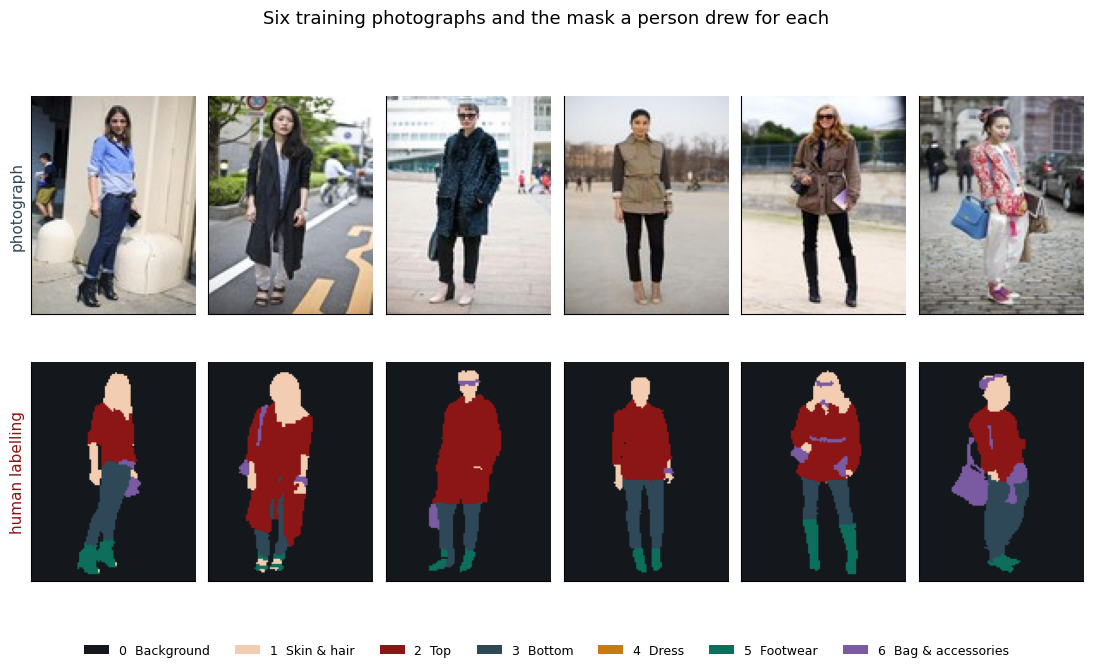

In [ ]:
fig, axes = plt.subplots(2, 6, figsize=(11, 6.4))
for k in range(6):
    i = tr[k]
    axes[0, k].imshow(IMAGES[i])
    axes[1, k].imshow(colourise(MASKS[i]))
    for r in (0, 1): axes[r, k].set_xticks([]); axes[r, k].set_yticks([])
axes[0, 0].set_ylabel("photograph", fontsize=11, color=SLATE)
axes[1, 0].set_ylabel("human labelling", fontsize=11, color=MAROON)
fig.legend(handles=LEGEND, loc="lower center", ncol=7, frameon=False,
           bbox_to_anchor=(0.5, -0.04), fontsize=9)
fig.suptitle("Six training photographs and the mask a person drew for each",
             y=0.99, fontsize=13)
plt.tight_layout(); plt.show()

Look at the bottom row. Somebody sat down and coloured in every one of those pixels by
hand. That is why segmentation datasets are small, and it is worth remembering whenever
you are tempted to ask for more labelled data.

## 2. The trap: why accuracy is the wrong measure here

Count how many pixels belong to each class and a problem appears immediately.

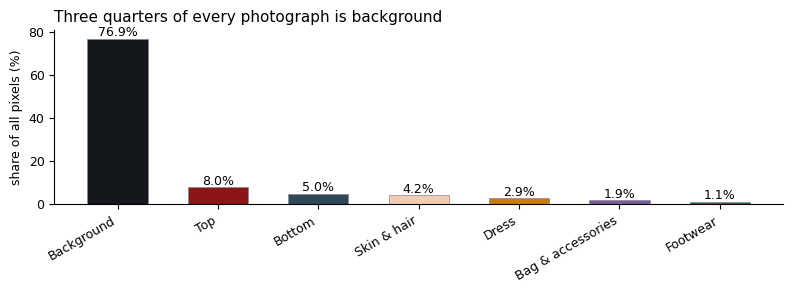

A model that predicts 'Background' for every single pixel would score
  76.9% pixel accuracy  —  and be completely worthless.

Footwear is 1.1% of pixels. Ignoring shoes entirely costs almost nothing
in accuracy, which is exactly why we cannot use accuracy.


In [ ]:
share = np.bincount(MASKS[tr].ravel(), minlength=7) / MASKS[tr].size
o = np.argsort(-share)

fig, ax = plt.subplots(figsize=(8, 3.0))
ax.bar([CLASSES[i] for i in o], share[o]*100, color=[PALETTE[i]/255 for i in o],
       edgecolor="#888", linewidth=0.5, width=0.6)
ax.set_ylabel("share of all pixels (%)")
ax.tick_params(axis="x", rotation=30)
for l in ax.get_xticklabels(): l.set_ha("right")
for k, i in enumerate(o):
    ax.text(k, share[i]*100 + 1.2, f"{share[i]:.1%}", ha="center", fontsize=9)
ax.set_title("Three quarters of every photograph is background", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

print(f"A model that predicts 'Background' for every single pixel would score")
print(f"  {share[0]:.1%} pixel accuracy  —  and be completely worthless.")
print(f"\nFootwear is {share[5]:.1%} of pixels. Ignoring shoes entirely costs almost nothing")
print("in accuracy, which is exactly why we cannot use accuracy.")

### Intersection over Union

The standard measure for segmentation asks, for each class separately:

> of all the pixels that are *either* predicted as "Footwear" *or* truly are "Footwear",
> what fraction did we get right?

That is **Intersection over Union** — the overlap between prediction and truth, divided
by their combined area. Predict no footwear at all and IoU for footwear is **zero**, no
matter how much background you got right. Averaged across the seven classes it cannot be
gamed by the easy ones.

In [ ]:
def iou_per_class(pred, true, n=7):
    out = []
    for c in range(n):
        p, t = (pred == c), (true == c)
        union = (p | t).sum()
        out.append(np.nan if union == 0 else (p & t).sum() / union)
    return np.array(out, dtype=float)

# demonstrate on the "predict background everywhere" model
dummy = np.zeros_like(MASKS[te])
d_iou = iou_per_class(dummy, MASKS[te])
print(f"{'Class':<20}{'IoU':>8}")
print("-" * 28)
for c, v in zip(CLASSES, d_iou):
    print(f"{c:<20}{v:>8.3f}")
print("-" * 28)
print(f"{'mean IoU':<20}{np.nanmean(d_iou):>8.3f}   <- the lazy model, properly scored")
print(f"{'pixel accuracy':<20}{(dummy == MASKS[te]).mean():>8.3f}   <- the same model, flattered")

Class                    IoU
----------------------------
Background             0.770
Skin & hair            0.000
Top                    0.000
Bottom                 0.000
Dress                  0.000
Footwear               0.000
Bag & accessories      0.000
----------------------------
mean IoU               0.110   <- the lazy model, properly scored
pixel accuracy         0.770   <- the same model, flattered


## 3. Prepare the tensors

Images scale to 0-1. Masks stay as whole numbers — they are class labels, not brightnesses.

In [ ]:
def build(idx):
    X = torch.tensor(IMAGES[idx], dtype=torch.float32).permute(0, 3, 1, 2) / 255.0
    Y = torch.tensor(MASKS[idx], dtype=torch.long)
    return X, Y

Xtr, Ytr = build(tr); Xva, Yva = build(va); Xte, Yte = build(te)

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(Xtr, Ytr), batch_size=16, shuffle=True, generator=g)
val_loader   = DataLoader(TensorDataset(Xva, Yva), batch_size=32)
test_loader  = DataLoader(TensorDataset(Xte, Yte), batch_size=32)

print(f"images {tuple(Xtr.shape)}   float 0-1")
print(f"masks  {tuple(Ytr.shape)}   integers 0-6")
print(f"batches per epoch: {len(train_loader)}")

images (800, 3, 128, 96)   float 0-1
masks  (800, 128, 96)   integers 0-6
batches per epoch: 50


## 4. The hourglass, and the problem it creates

Here is the central difficulty of segmentation, and it is worth understanding before we
write a single line of the model.

To recognise a coat, the network has to **look at a large region** — you cannot tell a
coat from a shirt by staring at one pixel. Getting that wide view means pooling: shrink
the picture, again and again, until each unit sees a big chunk of the original.

But the answer we need is **one label per pixel, at full resolution**. So having
shrunk the picture down, we have to build it back up.

Down, then up. That is the hourglass.

**And here is the catch.** Watch what shrinking actually destroys.

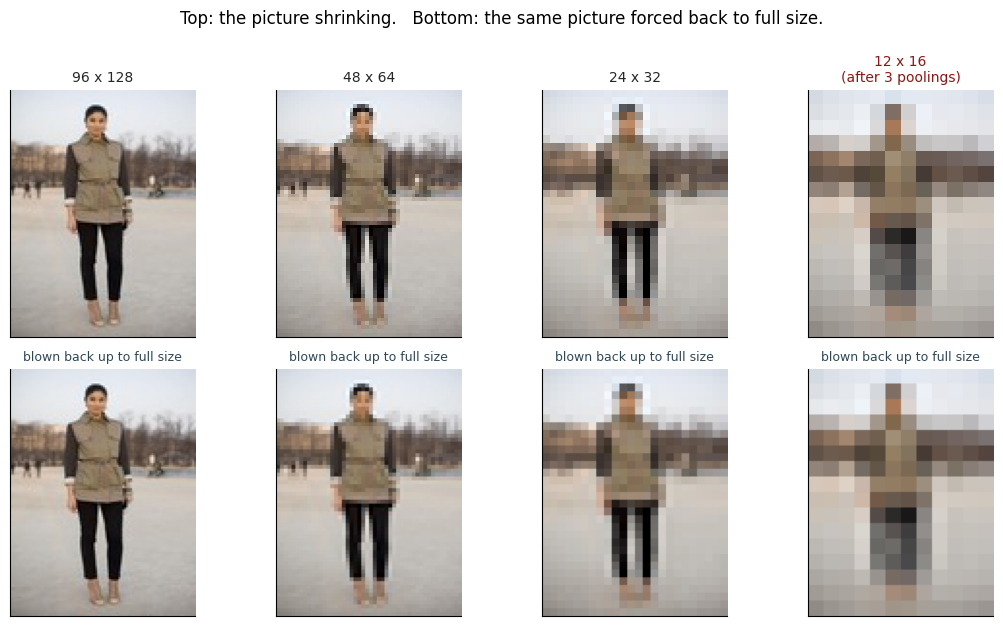

In [ ]:
demo = int(tr[3])
img = Image.fromarray(IMAGES[demo])
stages = [(W, H), (W//2, H//2), (W//4, H//4), (W//8, H//8)]

fig, axes = plt.subplots(2, 4, figsize=(11, 6.2))
for k, (w, h) in enumerate(stages):
    small = img.resize((w, h), Image.LANCZOS)
    axes[0, k].imshow(small)
    axes[0, k].set_title(f"{w} x {h}" + ("\n(after 3 poolings)" if k == 3 else ""),
                         fontsize=10, color=MAROON if k == 3 else "#262626")
    axes[1, k].imshow(small.resize((W, H), Image.NEAREST))
    axes[1, k].set_title("blown back up to full size", fontsize=9, color=SLATE)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Top: the picture shrinking.   Bottom: the same picture forced back to full size.",
             y=1.00, fontsize=12)
plt.tight_layout(); plt.show()

The bottom-right image is what the network has to work with at the bottom of the
hourglass. The person is still recognisable — you could still say "that is a coat" — but
the **edges are gone**. The boundary between coat and background is a smear. The shoes
have dissolved entirely.

No amount of upsampling recovers that. The information is not blurred, it is **deleted**.

> ### The fix: skip connections
>
> Copy the high-resolution feature maps from the way **down** and hand them directly to
> the matching layer on the way **up**.
>
> The deep path carries **what** the thing is. The skip carries **where its edges are**.
> Join them and you get both.
>
> That is U-Net, and we are about to prove it is necessary by building the same network
> without skips and watching it fail.

### The architecture, drawn

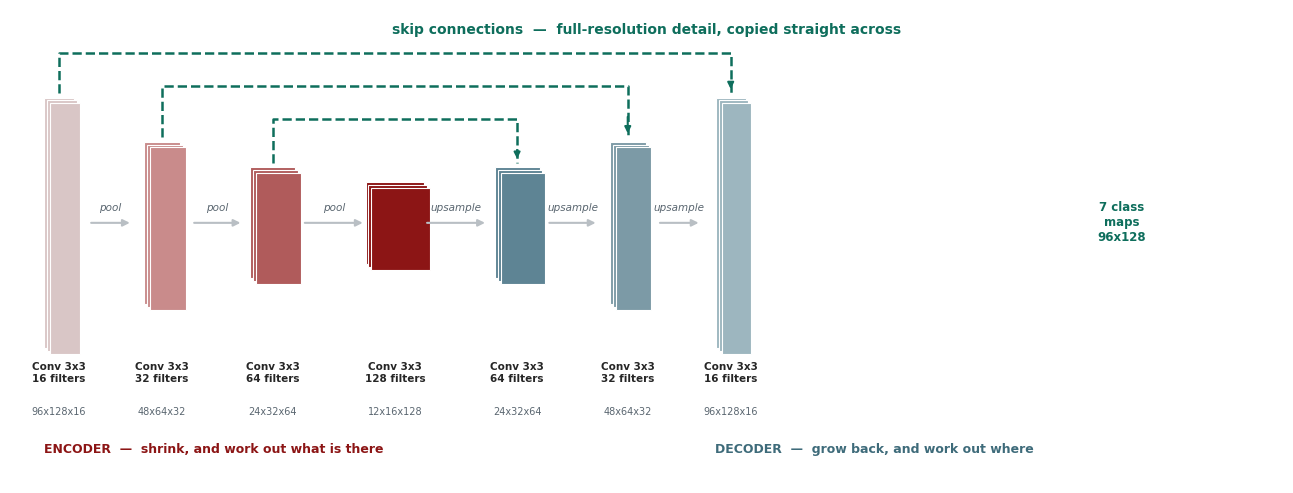

In [ ]:
def draw_hourglass(with_skips=True):
    fig, ax = plt.subplots(figsize=(13, 5.0))
    ax.set_xlim(0, 13); ax.set_ylim(0, 5.0); ax.axis("off")
    CY = 2.75

    enc = [("Conv 3x3\n16 filters", 96, 16, "#D9C6C6", "96x128x16"),
           ("Conv 3x3\n32 filters", 48, 32, "#C98B8B", "48x64x32"),
           ("Conv 3x3\n64 filters", 24, 64, "#B05B5B", "24x32x64")]
    bott = ("Conv 3x3\n128 filters", 12, 128, "#8C1515", "12x16x128")
    dec = [("Conv 3x3\n64 filters", 24, 64, "#5E8494", "24x32x64"),
           ("Conv 3x3\n32 filters", 48, 32, "#7C9AA6", "48x64x32"),
           ("Conv 3x3\n16 filters", 96, 16, "#9DB6BF", "96x128x16")]

    xs, blocks = [], enc + [bott] + dec
    x = 0.35
    for name, side, depth, col, shape in blocks:
        h = 0.45 + 2.20 * (side / 96) ** 0.8
        w = 0.18 + 0.42 * (depth / 128) ** 0.6
        y = CY - h / 2
        for k in range(3):
            ax.add_patch(Rectangle((x + k*0.03, y - k*0.03), w, h, fc=col, ec="white", lw=0.8))
        ax.text(x + w/2, 1.28, name, ha="center", va="top", fontsize=7.5,
                fontweight="bold", color="#262626")
        ax.text(x + w/2, 0.80, shape, ha="center", va="top", fontsize=7, color="#5A6670")
        xs.append((x + w/2, y + h))
        x += w + 0.72

    for i in range(len(blocks) - 1):
        x0 = xs[i][0] + 0.30; x1 = xs[i+1][0] - 0.30
        ax.add_patch(FancyArrowPatch((x0, CY), (x1, CY), arrowstyle="-|>",
                                     mutation_scale=10, color=GREY, lw=1.5))
    for i, lab in [(0, "pool"), (1, "pool"), (2, "pool")]:
        ax.text((xs[i][0] + xs[i+1][0]) / 2, CY + 0.12, lab, ha="center",
                fontsize=7.5, color="#5A6670", style="italic")
    for i, lab in [(3, "upsample"), (4, "upsample"), (5, "upsample")]:
        ax.text((xs[i][0] + xs[i+1][0]) / 2, CY + 0.12, lab, ha="center",
                fontsize=7.5, color="#5A6670", style="italic")

    if with_skips:
        for a, b, lvl in [(0, 6, 4.55), (1, 5, 4.20), (2, 4, 3.85)]:
            xa, ya = xs[a]; xb, yb = xs[b]
            ax.plot([xa, xa, xb, xb], [ya + 0.05, lvl, lvl, yb + 0.05],
                    color=TEAL, lw=1.8, ls="--")
            ax.add_patch(FancyArrowPatch((xb - 0.001, lvl - 0.30), (xb, yb + 0.06),
                                         arrowstyle="-|>", mutation_scale=9, color=TEAL, lw=1.5))
        ax.text(6.5, 4.75, "skip connections  —  full-resolution detail, copied straight across",
                ha="center", fontsize=10, color=TEAL, fontweight="bold")

    ax.text(0.35, 0.32, "ENCODER  —  shrink, and work out what is there",
            fontsize=9, color=MAROON, fontweight="bold")
    ax.text(7.2, 0.32, "DECODER  —  grow back, and work out where",
            fontsize=9, color="#3E6B7A", fontweight="bold")
    ax.text(11.35, CY, "7 class\nmaps\n96x128", ha="center", va="center",
            fontsize=8.5, fontweight="bold", color=TEAL)
    plt.tight_layout(); plt.show()

draw_hourglass(with_skips=True)

Read it left to right. The picture halves three times, 96x128 down to 12x16, while the
number of filters doubles each time. Then it grows back the same way.

**One convolution per block.** Nothing repeated, nothing clever.

The dashed lines are the whole point. Each one carries a full-resolution feature map from
the descent and hands it to the matching block on the climb, where it is stacked
alongside whatever came up from below.

## 5. Two models: one with skips, one without

In [ ]:
class Hourglass(nn.Module):
    """Encoder-decoder for segmentation. Set skips=False to cripple it deliberately."""
    def __init__(self, n_classes=7, skips=True):
        super().__init__()
        self.skips = skips
        def conv(i, o):
            # BatchNorm keeps activations well-scaled layer to layer; without it this
            # network trains far more slowly and plateaus much lower.
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1),
                                 nn.BatchNorm2d(o), nn.ReLU())

        self.enc1, self.enc2, self.enc3 = conv(3, 16), conv(16, 32), conv(32, 64)
        self.bottleneck = conv(64, 128)
        # with skips the decoder also receives the encoder map, so its input is wider
        self.dec3 = conv(128 + (64 if skips else 0), 64)
        self.dec2 = conv(64  + (32 if skips else 0), 32)
        self.dec1 = conv(32  + (16 if skips else 0), 16)
        self.head = nn.Conv2d(16, n_classes, kernel_size=1)

    def up(self, x):
        # bilinear, not nearest: nearest leaves visible 2x2 stair-steps in the mask
        return F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)

    def forward(self, x):
        e1 = self.enc1(x)                       # 96 x 128
        e2 = self.enc2(F.max_pool2d(e1, 2))     # 48 x 64
        e3 = self.enc3(F.max_pool2d(e2, 2))     # 24 x 32
        b  = self.bottleneck(F.max_pool2d(e3, 2))   # 12 x 16

        u = self.up(b)
        u = self.dec3(torch.cat([u, e3], 1) if self.skips else u)
        u = self.up(u)
        u = self.dec2(torch.cat([u, e2], 1) if self.skips else u)
        u = self.up(u)
        u = self.dec1(torch.cat([u, e1], 1) if self.skips else u)
        return self.head(u)                     # 7 x 96 x 128

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

torch.manual_seed(SEED); unet = Hourglass(skips=True)
torch.manual_seed(SEED); plain = Hourglass(skips=False)
print(f"U-Net (with skips)        {n_params(unet):>9,} parameters")
print(f"Plain encoder-decoder     {n_params(plain):>9,} parameters")
print("\nThe only difference is whether the decoder is allowed to see the encoder's maps.")

U-Net (with skips)          243,527 parameters
Plain encoder-decoder       195,143 parameters

The only difference is whether the decoder is allowed to see the encoder's maps.


In [ ]:
x = Xtr[:1]
print(f"{'Stage':<26}{'Shape (C, H, W)':<22}")
print("-" * 48)
rows = [("input", x.shape[1:])]
e1 = unet.enc1(x);                    rows.append(("enc1", e1.shape[1:]))
e2 = unet.enc2(F.max_pool2d(e1, 2));  rows.append(("enc2  (after pool)", e2.shape[1:]))
e3 = unet.enc3(F.max_pool2d(e2, 2));  rows.append(("enc3  (after pool)", e3.shape[1:]))
b  = unet.bottleneck(F.max_pool2d(e3, 2)); rows.append(("bottleneck", b.shape[1:]))
u  = unet.dec3(torch.cat([F.interpolate(b, scale_factor=2), e3], 1)); rows.append(("dec3  (+ skip enc3)", u.shape[1:]))
u  = unet.dec2(torch.cat([F.interpolate(u, scale_factor=2), e2], 1)); rows.append(("dec2  (+ skip enc2)", u.shape[1:]))
u  = unet.dec1(torch.cat([F.interpolate(u, scale_factor=2), e1], 1)); rows.append(("dec1  (+ skip enc1)", u.shape[1:]))
rows.append(("output", unet.head(u).shape[1:]))
for name, shp in rows:
    print(f"{name:<26}{str(tuple(shp)):<22}")
print("\nOut the same size it went in — one prediction per pixel.")

Stage                     Shape (C, H, W)       
------------------------------------------------
input                     (3, 128, 96)          
enc1                      (16, 128, 96)         
enc2  (after pool)        (32, 64, 48)          
enc3  (after pool)        (64, 32, 24)          
bottleneck                (128, 16, 12)         
dec3  (+ skip enc3)       (64, 32, 24)          
dec2  (+ skip enc2)       (32, 64, 48)          
dec1  (+ skip enc1)       (16, 128, 96)         
output                    (7, 128, 96)          

Out the same size it went in — one prediction per pixel.


## 6. Training

Two details that matter for segmentation.

**Weighted loss.** Since background is 77% of pixels, we tell the loss function to care
more about the rare classes. Without this the network learns to paint everything dark and
stops.

**We score with mean IoU**, not accuracy, for the reason established in section 2.

In [ ]:
weights = torch.tensor((1.0 / (share + 1e-6)) ** 0.5, dtype=torch.float32)
weights = (weights / weights.mean()).to(DEVICE)
print("Loss weight per class:")
for c, w in zip(CLASSES, weights.cpu().numpy()):
    print(f"  {c:<20}{w:>6.2f}")


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    inter = np.zeros(7); union = np.zeros(7); loss_sum = n = 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        out = model(xb)
        loss_sum += F.cross_entropy(out, yb, weight=weights).item() * len(xb); n += len(xb)
        p = out.argmax(1).cpu().numpy(); t = yb.cpu().numpy()
        for c in range(7):
            pc, tc = (p == c), (t == c)
            inter[c] += (pc & tc).sum(); union[c] += (pc | tc).sum()
    per = np.where(union > 0, inter / np.maximum(union, 1), np.nan)
    return loss_sum / n, np.nanmean(per), per


def augment(x, y):
    """Flip image AND mask together, then jitter brightness. Doubles our 800 photos."""
    flip = torch.rand(len(x)) < 0.5
    x, y = x.clone(), y.clone()
    x[flip] = torch.flip(x[flip], dims=[3])      # image: (N,C,H,W) -> flip W
    y[flip] = torch.flip(y[flip], dims=[2])      # mask:  (N,H,W)   -> flip W
    x = torch.clamp(x * (0.8 + 0.4 * torch.rand(len(x), 1, 1, 1)), 0, 1)
    return x, y


def train(model, epochs=20, lr=3e-3, label="", use_aug=True):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    hist = {"train_loss": [], "val_loss": [], "val_miou": []}
    for ep in range(1, epochs + 1):
        model.train(); loss_sum = n = 0
        for xb, yb in train_loader:
            if use_aug: xb, yb = augment(xb, yb)
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = F.cross_entropy(model(xb), yb, weight=weights)
            loss.backward(); opt.step()
            loss_sum += loss.item() * len(xb); n += len(xb)
        sched.step()
        vl, miou, _ = evaluate(model, val_loader)
        hist["train_loss"].append(loss_sum/n); hist["val_loss"].append(vl)
        hist["val_miou"].append(miou)
        print(f"  {label} epoch {ep:>2}/{epochs}   train loss {loss_sum/n:.3f}   "
              f"val loss {vl:.3f}   val mIoU {miou:.3f}")
    return hist

Loss weight per class:
  Background            0.22
  Skin & hair           0.94
  Top                   0.67
  Bottom                0.86
  Dress                 1.12
  Footwear              1.82
  Bag & accessories     1.37


### Seeing the augmentation

Flipping is free extra training data, but **the mask must flip with the image** or you
are teaching the network nonsense. Check it visually before trusting it.

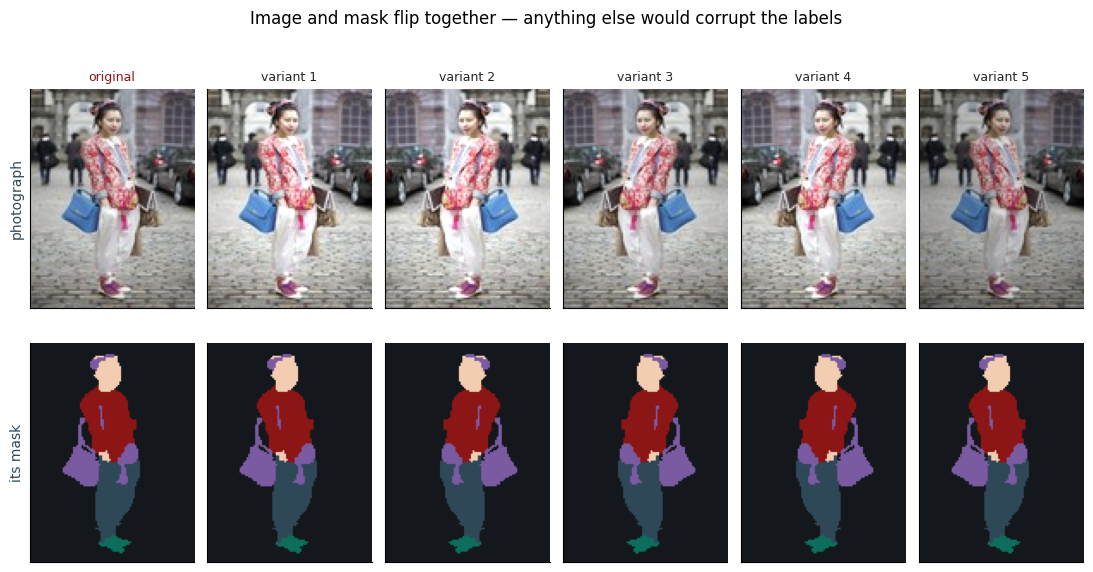

In [ ]:
torch.manual_seed(SEED)
k = int(tr[5])
xs = torch.tensor(IMAGES[[k]], dtype=torch.float32).permute(0,3,1,2)/255.
ys = torch.tensor(MASKS[[k]])
pairs = [(xs[0], ys[0])] + [tuple(t[0] for t in augment(xs, ys)) for _ in range(5)]

fig, axes = plt.subplots(2, 6, figsize=(11, 6.0))
for c, (xi, yi) in enumerate(pairs):
    axes[0, c].imshow(xi.permute(1,2,0).numpy())
    axes[1, c].imshow(colourise(yi.numpy()))
    axes[0, c].set_title("original" if c == 0 else f"variant {c}",
                         fontsize=9, color=MAROON if c == 0 else "#262626")
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
axes[0,0].set_ylabel("photograph", fontsize=10, color=SLATE)
axes[1,0].set_ylabel("its mask", fontsize=10, color=SLATE)
fig.suptitle("Image and mask flip together — anything else would corrupt the labels",
             y=1.00, fontsize=12)
plt.tight_layout(); plt.show()

### Three ingredients that make this work

Trained without them, this same architecture reaches only about **0.37** mean IoU with
soft, ragged masks. With them it reaches roughly **0.52**. None of them changes the
architecture — we still have one convolution per block.

| Ingredient | Why |
|---|---|
| **BatchNorm** after each convolution | Keeps activations well-scaled through the network. Without it, training crawls and plateaus early. |
| **Flip + brightness augmentation** | 800 photographs is very few. Flipping is label-safe for garments and effectively doubles the set. |
| **Bilinear upsampling** | Nearest-neighbour leaves visible 2x2 stair-steps in the output mask. |

Plus a **cosine learning-rate schedule**, which starts fast and finishes fine.

In [ ]:
EPOCHS = 20
t0 = time.time()
print("PLAIN ENCODER-DECODER  (no skip connections)\n")
hist_plain = train(plain, EPOCHS, label="plain")
print(f"\n{'-'*70}\nU-NET  (with skip connections)\n")
hist_unet = train(unet, EPOCHS, label="unet ")
print(f"\nBoth trained in {time.time()-t0:.0f} seconds")

PLAIN ENCODER-DECODER  (no skip connections)

  plain epoch  1/20   train loss 1.357   val loss 1.127   val mIoU 0.285
  plain epoch  2/20   train loss 0.966   val loss 0.924   val mIoU 0.333
  plain epoch  3/20   train loss 0.856   val loss 0.933   val mIoU 0.302
  plain epoch  4/20   train loss 0.790   val loss 0.814   val mIoU 0.365
  plain epoch  5/20   train loss 0.744   val loss 0.817   val mIoU 0.377
  plain epoch  6/20   train loss 0.704   val loss 0.767   val mIoU 0.401
  plain epoch  7/20   train loss 0.668   val loss 0.737   val mIoU 0.418
  plain epoch  8/20   train loss 0.644   val loss 0.742   val mIoU 0.402
  plain epoch  9/20   train loss 0.626   val loss 0.726   val mIoU 0.400
  plain epoch 10/20   train loss 0.594   val loss 0.695   val mIoU 0.440
  plain epoch 11/20   train loss 0.572   val loss 0.690   val mIoU 0.444
  plain epoch 12/20   train loss 0.558   val loss 0.719   val mIoU 0.455
  plain epoch 13/20   train loss 0.543   val loss 0.668   val mIoU 0.451
  pla

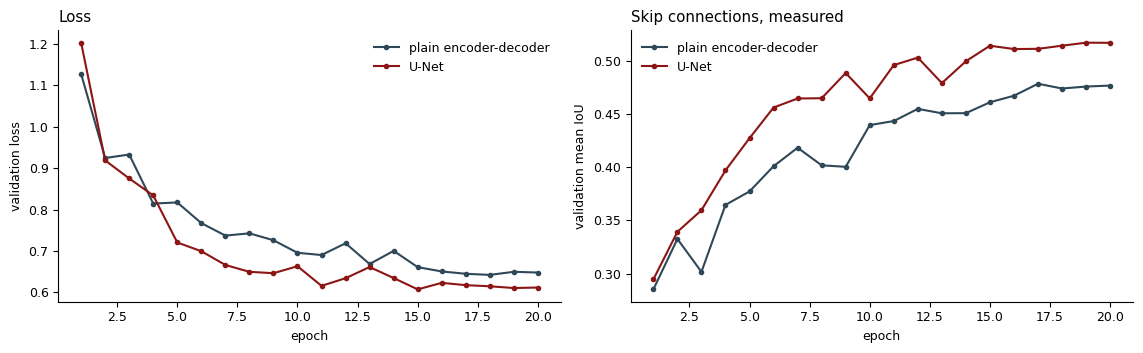

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
ep = range(1, EPOCHS + 1)
axes[0].plot(ep, hist_plain["val_loss"], "-o", ms=3, color=SLATE, label="plain encoder-decoder")
axes[0].plot(ep, hist_unet["val_loss"],  "-o", ms=3, color=MAROON, label="U-Net")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("validation loss")
axes[0].set_title("Loss", loc="left"); axes[0].legend(frameon=False)

axes[1].plot(ep, hist_plain["val_miou"], "-o", ms=3, color=SLATE, label="plain encoder-decoder")
axes[1].plot(ep, hist_unet["val_miou"],  "-o", ms=3, color=MAROON, label="U-Net")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation mean IoU")
axes[1].set_title("Skip connections, measured", loc="left"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

## 7. The payoff: what the two networks actually produce

This is the figure the whole notebook was built for. Same photograph, same training, same
number of parameters give or take. The only difference is whether the decoder could see
the encoder's high-resolution maps.

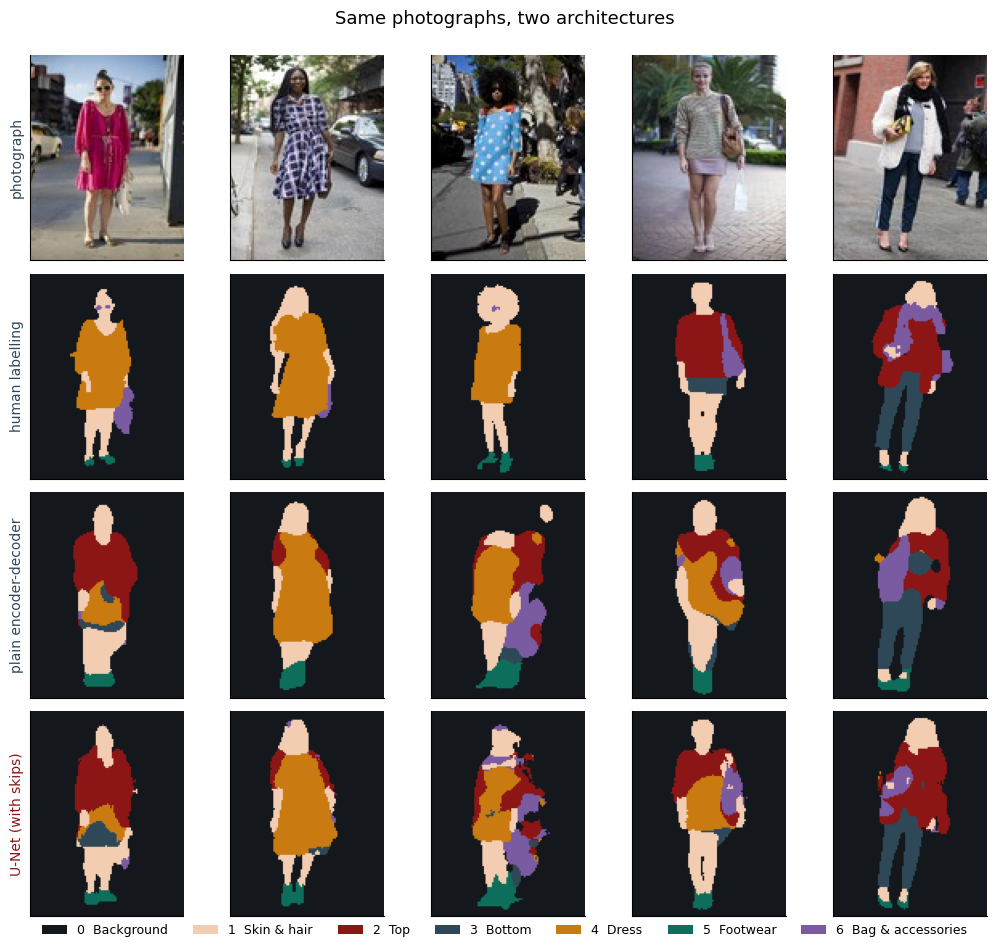

In [ ]:
@torch.no_grad()
def predict(model, X):
    model.eval(); out = []
    for i in range(0, len(X), 32):
        out.append(model(X[i:i+32].to(DEVICE)).argmax(1).cpu().numpy())
    return np.concatenate(out)

pred_plain = predict(plain, Xte)
pred_unet  = predict(unet,  Xte)

picks = [0, 3, 7, 11, 15]
fig, axes = plt.subplots(4, len(picks), figsize=(2.1*len(picks), 9.2))
rows = [("photograph", None), ("human labelling", MASKS[te]),
        ("plain encoder-decoder", pred_plain), ("U-Net (with skips)", pred_unet)]
for c, k in enumerate(picks):
    axes[0, c].imshow(IMAGES[te[k]])
    for r, (name, arr) in enumerate(rows[1:], start=1):
        axes[r, c].imshow(colourise(arr[k]))
for r, (name, _) in enumerate(rows):
    axes[r, 0].set_ylabel(name, fontsize=10,
                          color=MAROON if "U-Net" in name else SLATE)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
fig.legend(handles=LEGEND, loc="lower center", ncol=7, frameon=False,
           bbox_to_anchor=(0.5, -0.02), fontsize=9)
fig.suptitle("Same photographs, two architectures", y=1.00, fontsize=13)
plt.tight_layout(); plt.show()

Compare rows three and four against row two.

The plain encoder-decoder gets the **rough idea** right — roughly where the person is,
roughly that they are wearing something. But the edges are soft and blobby, and it
routinely paints an entire dress as "Top" because it is drawing at 12x16 and stretching
the result. Bags vanish almost completely.

The U-Net's boundaries follow the actual garment, and the small items survive. That
difference comes entirely from three dashed lines in the diagram.

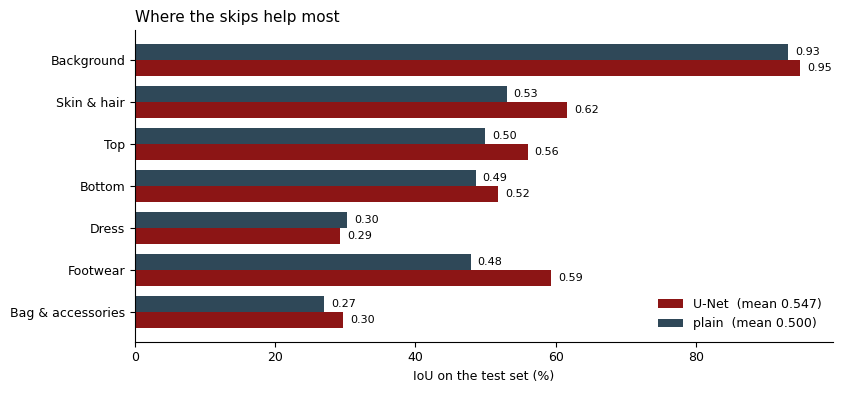

Model                         mean IoU   pixel acc
--------------------------------------------------
Predict background always        0.110       0.770
Plain encoder-decoder            0.500       0.879
U-Net (with skips)               0.547       0.898


In [ ]:
_, miou_plain, per_plain = evaluate(plain, test_loader)
_, miou_unet,  per_unet  = evaluate(unet,  test_loader)

y = np.arange(7); h = 0.38
fig, ax = plt.subplots(figsize=(8.5, 4.0))
ax.barh(y + h/2, per_unet*100,  h, color=MAROON, label=f"U-Net  (mean {miou_unet:.3f})")
ax.barh(y - h/2, per_plain*100, h, color=SLATE,  label=f"plain  (mean {miou_plain:.3f})")
ax.set_yticks(y, CLASSES); ax.invert_yaxis()
ax.set_xlabel("IoU on the test set (%)")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Where the skips help most", loc="left", fontsize=11)
for i in range(7):
    ax.text(per_unet[i]*100 + 1, i + h/2, f"{per_unet[i]:.2f}", va="center", fontsize=8)
    ax.text(per_plain[i]*100 + 1, i - h/2, f"{per_plain[i]:.2f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'Model':<28}{'mean IoU':>10}{'pixel acc':>12}")
print("-" * 50)
for name, p, m in [("Predict background always", np.zeros_like(MASKS[te]), None),
                   ("Plain encoder-decoder", pred_plain, miou_plain),
                   ("U-Net (with skips)", pred_unet, miou_unet)]:
    mi = np.nanmean(iou_per_class(p, MASKS[te])) if m is None else m
    print(f"{name:<28}{mi:>10.3f}{(p == MASKS[te]).mean():>12.3f}")

**Read the per-class chart, not just the average.** The two models are close on
Background, Top and Bottom — the big chunky regions that survive being shrunk to 12x16.
Almost everything the skips buy is in the *small* classes: footwear, bags, and the
boundary between skin and garment.

That is the hourglass argument confirmed. Detail destroyed by pooling costs you nothing
on a coat filling half the frame, and costs you everything on a handbag.

Note the absolute numbers are still modest. With 800 labelled photographs this is a
teaching model, not a shippable one — see the exercises.

Read the bottom table carefully too, because it contains the lesson of section 2.

The lazy model's **pixel accuracy** is respectable. Its **mean IoU** is near zero. If you
had reported accuracy you would have shipped a model that paints the whole photograph
dark and calls it a day.

## 8. Inside the hourglass

One photograph, and what the network is holding at each stage on the way down and back up.

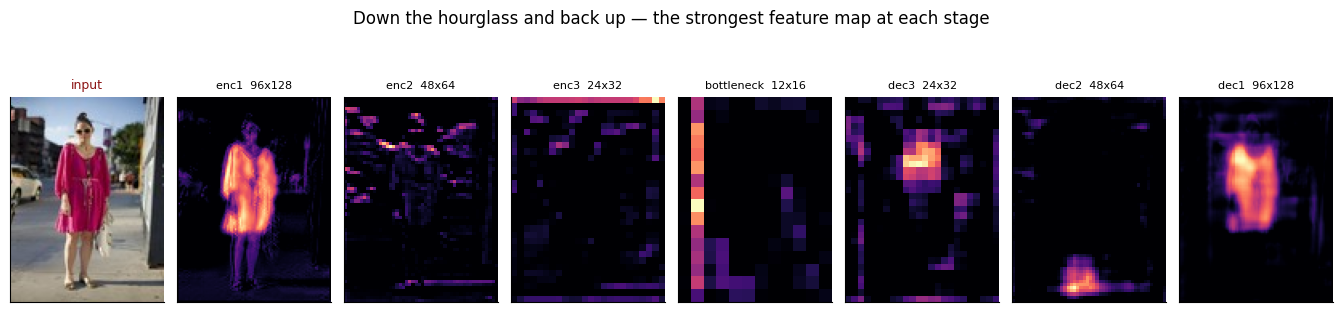

In [ ]:
probe = Xte[picks[0]:picks[0]+1].to(DEVICE)
unet.eval()
with torch.no_grad():
    e1 = unet.enc1(probe); e2 = unet.enc2(F.max_pool2d(e1, 2))
    e3 = unet.enc3(F.max_pool2d(e2, 2)); b = unet.bottleneck(F.max_pool2d(e3, 2))
    u3 = unet.dec3(torch.cat([F.interpolate(b, scale_factor=2), e3], 1))
    u2 = unet.dec2(torch.cat([F.interpolate(u3, scale_factor=2), e2], 1))
    u1 = unet.dec1(torch.cat([F.interpolate(u2, scale_factor=2), e1], 1))

stages = [("enc1  96x128", e1), ("enc2  48x64", e2), ("enc3  24x32", e3),
          ("bottleneck  12x16", b), ("dec3  24x32", u3), ("dec2  48x64", u2),
          ("dec1  96x128", u1)]
fig, axes = plt.subplots(1, len(stages) + 1, figsize=(13.5, 2.9))
axes[0].imshow(IMAGES[te[picks[0]]]); axes[0].set_title("input", fontsize=9, color=MAROON)
for ax, (name, act) in zip(axes[1:], stages):
    fm = act[0].cpu().numpy()
    ax.imshow(fm[int(np.argmax(fm.reshape(len(fm), -1).max(1)))], cmap="magma")
    ax.set_title(name, fontsize=8)
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Down the hourglass and back up — the strongest feature map at each stage",
             y=1.10, fontsize=12)
plt.tight_layout(); plt.show()

Watch the resolution collapse to 12x16 in the middle and climb back out. The maps on the
way up are **sharper than the ones at the bottleneck**, and they could not be — there is
no detail down there to recover. That sharpness arrives through the skip connections.

## 9. Shop the look

Now the business payoff. We have a label for every pixel, so we can cut each garment out
of the photograph and send it to the catalog search as its own image.

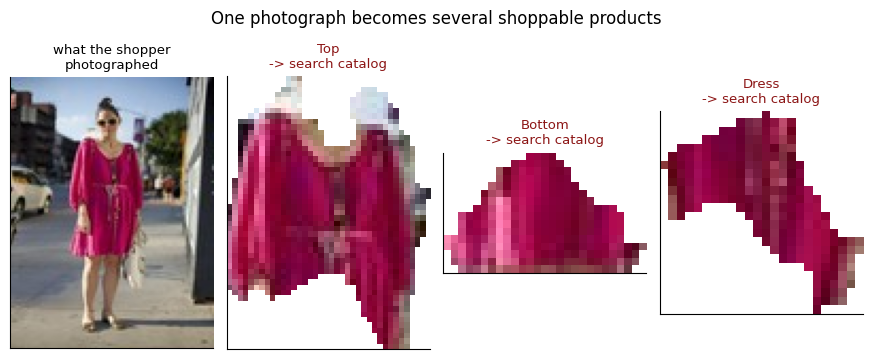

Each crop on the right is a standalone image that can now be matched
against product photographs using last session's classifier.


In [ ]:
from scipy.ndimage import label as cc_label, binary_closing

def extract(idx, cls, min_frac=0.012):
    """Cut one garment out. Keep only its largest solid blob, not scattered pixels."""
    m = (pred_unet[idx] == cls)
    m = binary_closing(m, np.ones((3, 3)))          # tidy ragged edges
    lab, n = cc_label(m)
    if n == 0: return None
    sizes = np.bincount(lab.ravel()); sizes[0] = 0
    m = (lab == sizes.argmax())                     # largest connected region only
    if m.sum() < min_frac * m.size: return None     # too small to be a real garment
    out = IMAGES[te[idx]].copy(); out[~m] = 255
    ys, xs = np.where(m)
    return out[ys.min():ys.max()+1, xs.min():xs.max()+1]

shoppable = [2, 3, 4, 5, 6]      # the classes a marketplace can actually sell
k = picks[0]
found = [(c, extract(k, c)) for c in shoppable]
found = [(c, im) for c, im in found if im is not None]

fig, axes = plt.subplots(1, len(found) + 1, figsize=(2.2*(len(found)+1), 3.6))
axes[0].imshow(IMAGES[te[k]]); axes[0].set_title("what the shopper\nphotographed", fontsize=9.5)
for ax, (c, im) in zip(axes[1:], found):
    ax.imshow(im); ax.set_title(f"{CLASSES[c]}\n-> search catalog", fontsize=9.5, color=MAROON)
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("One photograph becomes several shoppable products", y=1.02, fontsize=12)
plt.tight_layout(); plt.show()

print("Each crop on the right is a standalone image that can now be matched")
print("against product photographs using last session's classifier.")

## 10. Where it fails

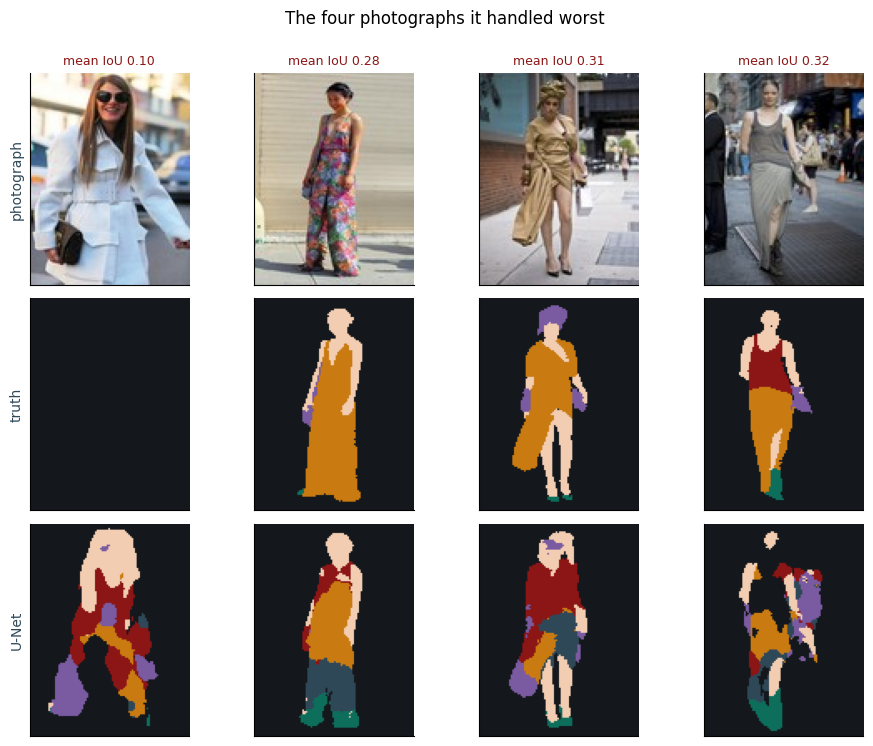

In [ ]:
ious = np.array([np.nanmean(iou_per_class(pred_unet[i], MASKS[te][i])) for i in range(len(te))])
worst = np.argsort(ious)[:4]

fig, axes = plt.subplots(3, 4, figsize=(9.5, 7.4))
for c, i in enumerate(worst):
    axes[0, c].imshow(IMAGES[te[i]])
    axes[1, c].imshow(colourise(MASKS[te][i]))
    axes[2, c].imshow(colourise(pred_unet[i]))
    axes[0, c].set_title(f"mean IoU {ious[i]:.2f}", fontsize=9, color=MAROON)
for r, name in enumerate(["photograph", "truth", "U-Net"]):
    axes[r, 0].set_ylabel(name, fontsize=10, color=SLATE)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("The four photographs it handled worst", y=1.00, fontsize=12)
plt.tight_layout(); plt.show()

Look for the pattern. Unusual poses, several people in frame, garments in colours close
to the background, and outfits the 800 training images simply never contained.

With a thousand hand-labelled photographs this is roughly the ceiling. The fix is more
labelled data or a pretrained encoder — not a deeper network.

In [ ]:
torch.save({"state_dict": unet.state_dict(), "classes": CLASSES,
            "mean_iou": float(miou_unet), "size": [W, H]}, "fashion_unet.pt")
torch.manual_seed(SEED); again = Hourglass(skips=True).to(DEVICE)
again.load_state_dict(torch.load("fashion_unet.pt", map_location=DEVICE,
                                 weights_only=False)["state_dict"])
_, m, _ = evaluate(again, test_loader)
print(f"Saved fashion_unet.pt — reloaded and verified at mean IoU {m:.3f}")

Saved fashion_unet.pt — reloaded and verified at mean IoU 0.547


## Summary

1. Segmentation labels **every pixel**, which is what makes a photograph shoppable.
2. Pixel labelling is expensive, so segmentation datasets are small.
3. Accuracy is the wrong measure when one class is 77% of the pixels. Use mean IoU.
4. To know *what* something is you must shrink the picture. To say *where* it is you must
   grow it back. That is the hourglass.
5. Shrinking **deletes** boundary detail. Upsampling cannot invent it back.
6. Skip connections carry the detail across. The deep path says what; the skip says where.
7. Removing them costs most on the small classes — shoes and bags — exactly as predicted.
8. The output regions become crops you can search a catalog with.

---

## Exercises

1. **Move the bottleneck.** Add a fourth pooling stage so the picture reaches 6x8. Does
   more context help, or does the extra shrinking cost more than it gains?

2. **Break one skip.** Keep `enc1`'s skip but drop `enc2` and `enc3`. Which classes
   degrade? Does that match your prediction from the hourglass figure?

3. **Turn off the loss weights.** Set `weights = None`. Watch mean IoU collapse while
   pixel accuracy barely moves, and explain the discrepancy in two sentences.

4. **Add a Dice loss** alongside cross-entropy. Dice optimises overlap directly, which is
   closer to what IoU measures. Does it help the rare classes?

5. **Reuse last session's encoder.** Load the trained classifier's convolution layers as
   this network's encoder and fine-tune. Fewer than a thousand images is exactly the
   situation where that should pay off.